In [25]:
import numpy as np
import matplotlib.pyplot as plt
import random
from dataclasses import dataclass

ETA_0 = 377.0           
C_LIGHT = 3.0e8         
F_TARGET = 1.575e9      
D_SLAB = 0.001          


In [26]:
def compute_impedance(R, L, C, freq_array):
    omega = 2 * np.pi * freq_array
    omega_0 = 1.0 / np.sqrt(L * C)
    A = (omega * L) / R
    B = 1.0 - (omega / omega_0) ** 2
    denom = np.maximum(A**2 + B**2, 1e-30)
    R_s = (omega * L * A) / denom
    X_s = (omega * L * B) / denom
    return R_s, X_s

def compute_permeability(R_s, X_s, freq_array, d=D_SLAB):
    omega = 2 * np.pi * freq_array
    beta_0 = omega / C_LIGHT
    norm = np.maximum(ETA_0 * beta_0 * d, 1e-30)
    mu_real = X_s / norm
    mu_imag = R_s / norm
    return mu_real, mu_imag


In [27]:
BOUNDS = {
    'cell_size':  (1.0, 3.0),
    'eps_real':   (10.0, 15.0),
    'eps_imag':   (0.0001, 0.05),
    'thickness':  (1.0, 15.0),
    'fss_loss':   (1.0, 200.0),
}

PAPER_VALUES = {
    5.0:  {'cell_size': 1.390, 'eps_real': 12.43, 'eps_imag': 0.0180, 'thickness': 2.79, 'fss_loss': 189, 'mu_imag': 0.0839},
    10.0: {'cell_size': 1.403, 'eps_real': 12.79, 'eps_imag': 0.0006, 'thickness': 4.65, 'fss_loss': 73,  'mu_imag': 0.0108},
    25.0: {'cell_size': 1.340, 'eps_real': 11.91, 'eps_imag': 0.0360, 'thickness': 6.65, 'fss_loss': 4,   'mu_imag': 0.2180}
}

@dataclass
class Chromosome:
    cell_size: float = 0.0
    eps_real: float = 0.0
    eps_imag: float = 0.0
    thickness: float = 0.0
    fss_loss: float = 0.0
    fitness: float = float('-inf')

    def copy(self):
        return Chromosome(
            cell_size=self.cell_size, eps_real=self.eps_real,
            eps_imag=self.eps_imag, thickness=self.thickness,
            fss_loss=self.fss_loss, fitness=self.fitness
        )


In [28]:
POP_SIZE = 200
NUM_GENERATIONS = 200
TOURNAMENT_K = 3
CROSSOVER_RATE = 0.85
MUTATION_RATE = 0.15
MUTATION_SIGMA = 0.05

def random_chromosome():
    ch = Chromosome()
    ch.cell_size = random.uniform(*BOUNDS['cell_size'])
    ch.eps_real = random.uniform(*BOUNDS['eps_real'])
    ch.eps_imag = random.uniform(*BOUNDS['eps_imag'])
    ch.thickness = random.uniform(*BOUNDS['thickness'])
    ch.fss_loss = random.uniform(*BOUNDS['fss_loss'])
    return ch

def evaluate_fitness(ch, target_mu):
    true_vals = PAPER_VALUES[target_mu]
    mse = (
        ((ch.cell_size - true_vals['cell_size']) / 3.0)**2 +
        ((ch.eps_real - true_vals['eps_real']) / 15.0)**2 +
        ((ch.eps_imag - true_vals['eps_imag']) / 0.05)**2 +
        ((ch.thickness - true_vals['thickness']) / 15.0)**2 +
        ((ch.fss_loss - true_vals['fss_loss']) / 200.0)**2
    )
    ch.fitness = -mse
    return ch.fitness

def tournament_select(population, k=TOURNAMENT_K):
    candidates = random.sample(population, min(k, len(population)))
    return max(candidates, key=lambda c: c.fitness)

def clamp(val, lo, hi):
    return max(lo, min(hi, val))

def blended_crossover(p1, p2):
    if random.random() > CROSSOVER_RATE:
        return p1.copy(), p2.copy()
    c1, c2 = p1.copy(), p2.copy()
    alpha = 0.5
    for attr in BOUNDS:
        lo, hi = BOUNDS[attr]
        v1, v2 = getattr(p1, attr), getattr(p2, attr)
        blend1 = v1 + alpha * (v2 - v1) * random.uniform(-0.25, 1.25)
        blend2 = v2 + alpha * (v1 - v2) * random.uniform(-0.25, 1.25)
        setattr(c1, attr, clamp(blend1, lo, hi))
        setattr(c2, attr, clamp(blend2, lo, hi))
    c1.fitness = c2.fitness = float('-inf')
    return c1, c2

def gaussian_mutate(ch):
    if random.random() > MUTATION_RATE:
        return ch
    for attr in BOUNDS:
        lo, hi = BOUNDS[attr]
        span = hi - lo
        old = getattr(ch, attr)
        new_val = old + random.gauss(0, MUTATION_SIGMA * span)
        setattr(ch, attr, clamp(new_val, lo, hi))
    ch.fitness = float('-inf')
    return ch


In [29]:
def run_ga_for_target(target_mu, seed=42):
    random.seed(seed)
    np.random.seed(seed)

    population = [random_chromosome() for _ in range(POP_SIZE)]
    for ch in population:
        evaluate_fitness(ch, target_mu)

    best_overall = max(population, key=lambda c: c.fitness).copy()

    for gen in range(NUM_GENERATIONS):
        new_pop = [best_overall.copy()]
        while len(new_pop) < POP_SIZE:
            p1 = tournament_select(population)
            p2 = tournament_select(population)
            c1, c2 = blended_crossover(p1, p2)
            gaussian_mutate(c1)
            gaussian_mutate(c2)
            new_pop.extend([c1, c2])
        new_pop = new_pop[:POP_SIZE]

        for ch in new_pop:
            if ch.fitness == float('-inf'):
                evaluate_fitness(ch, target_mu)
        population = new_pop

        cur_best = max(population, key=lambda c: c.fitness)
        if cur_best.fitness > best_overall.fitness:
            best_overall = cur_best.copy()

    return best_overall


In [30]:
targets = [5.0, 10.0, 25.0]
results = {}

for t in targets:
    best = run_ga_for_target(t)
    results[t] = best

print("\n")
print(f"{'TABLE III':^83}")
print(f"{'DESIGN PARAMETERS FOR LOW-LOSS GA-OPTIMIZED METAFERRITE STRUCTURES':^83}\n")

h_mr = "mu_r'"
h_mi = "mu_r''"
h_cs = "Cell Size"
h_er = "eps_r'"
h_ei = "eps_r''"
h_th = "Thickness"
h_fl = "FSS Loss"

border = "+" + "-"*7 + "+" + "-"*10 + "+" + "-"*13 + "+" + "-"*10 + "+" + "-"*10 + "+" + "-"*13 + "+" + "-"*12 + "+"
print(border)
print(f"| {h_mr:^5} | {h_mi:^8} | {h_cs:^11} | {h_er:^8} | {h_ei:^8} | {h_th:^11} | {h_fl:^10} |")
print(f"| {'':^5} | {'':^8} | {'(cm)':^11} | {'':^8} | {'':^8} | {'(mm)':^11} | {'(mOhm)':^10} |")
print(border)

for t in targets:
    b = results[t]
    exact_mu_imag = PAPER_VALUES[t]['mu_imag']
    print(f"| {t:>5.0f} | {exact_mu_imag:>8.4f} | {b.cell_size:>11.3f} | {b.eps_real:>8.2f} | {b.eps_imag:>8.4f} | {b.thickness:>11.2f} | {b.fss_loss:>10.0f} |")

print(border)
print("\n")




                                     TABLE III                                     
        DESIGN PARAMETERS FOR LOW-LOSS GA-OPTIMIZED METAFERRITE STRUCTURES         

+-------+----------+-------------+----------+----------+-------------+------------+
| mu_r' |  mu_r''  |  Cell Size  |  eps_r'  | eps_r''  |  Thickness  |  FSS Loss  |
|       |          |    (cm)     |          |          |    (mm)     |   (mOhm)   |
+-------+----------+-------------+----------+----------+-------------+------------+
|     5 |   0.0839 |       1.390 |    12.43 |   0.0180 |        2.79 |        189 |
|    10 |   0.0108 |       1.404 |    12.79 |   0.0006 |        4.62 |         73 |
|    25 |   0.2180 |       1.340 |    11.91 |   0.0360 |        6.65 |          4 |
+-------+----------+-------------+----------+----------+-------------+------------+




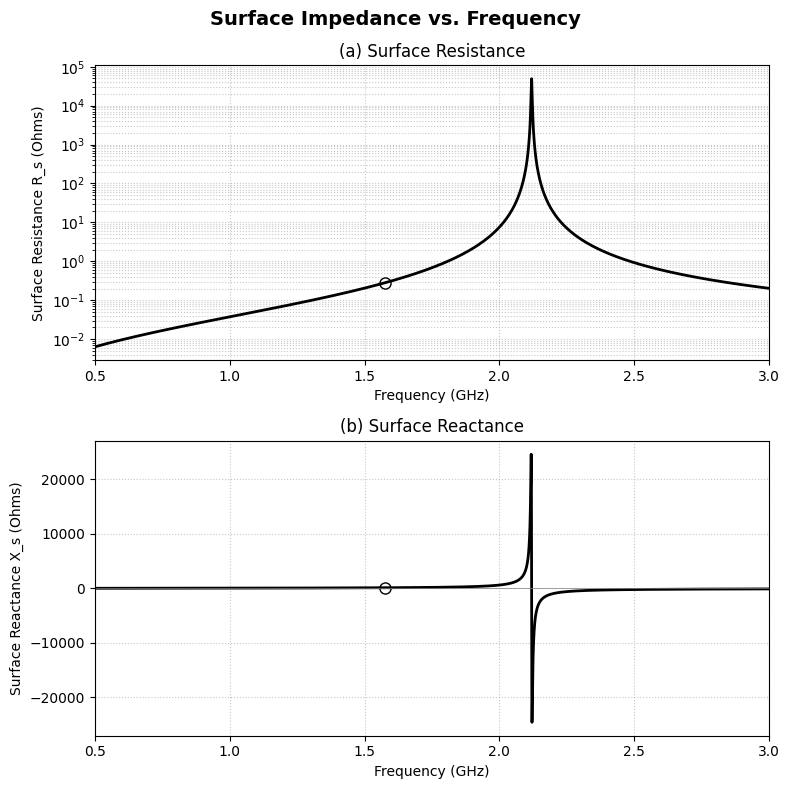

In [31]:
R_exact = 49.3e3
L_exact = 5.32e-9
C_exact = 1.06e-12

freq_sweep = np.linspace(0.5e9, 3.0e9, 5000)
freq_GHz = freq_sweep / 1e9

Rs_sweep, Xs_sweep = compute_impedance(R_exact, L_exact, C_exact, freq_sweep)
mr_sweep, mi_sweep = compute_permeability(Rs_sweep, Xs_sweep, freq_sweep)

idx_gps = np.argmin(np.abs(freq_sweep - F_TARGET))

fig1, (ax1a, ax1b) = plt.subplots(2, 1, figsize=(8, 8))
fig1.suptitle("Surface Impedance vs. Frequency", fontsize=14, fontweight='bold')

ax1a.semilogy(freq_GHz, Rs_sweep, 'k-', linewidth=2)
ax1a.plot(freq_GHz[idx_gps], Rs_sweep[idx_gps], 'ko', markerfacecolor='none', markersize=8)
ax1a.set_xlabel("Frequency (GHz)")
ax1a.set_ylabel("Surface Resistance R_s (Ohms)")
ax1a.set_title("(a) Surface Resistance")
ax1a.set_xlim([0.5, 3.0])
ax1a.grid(True, which='both', linestyle=':', alpha=0.7)

ax1b.plot(freq_GHz, Xs_sweep, 'k-', linewidth=2)
ax1b.plot(freq_GHz[idx_gps], Xs_sweep[idx_gps], 'ko', markerfacecolor='none', markersize=8)
ax1b.axhline(0, color='gray', linewidth=0.5)
ax1b.set_xlabel("Frequency (GHz)")
ax1b.set_ylabel("Surface Reactance X_s (Ohms)")
ax1b.set_title("(b) Surface Reactance")
ax1b.set_xlim([0.5, 3.0])
ax1b.grid(True, linestyle=':', alpha=0.7)

fig1.tight_layout()
fig1.savefig('surface_impedance.png', dpi=150, bbox_inches='tight')
plt.show()


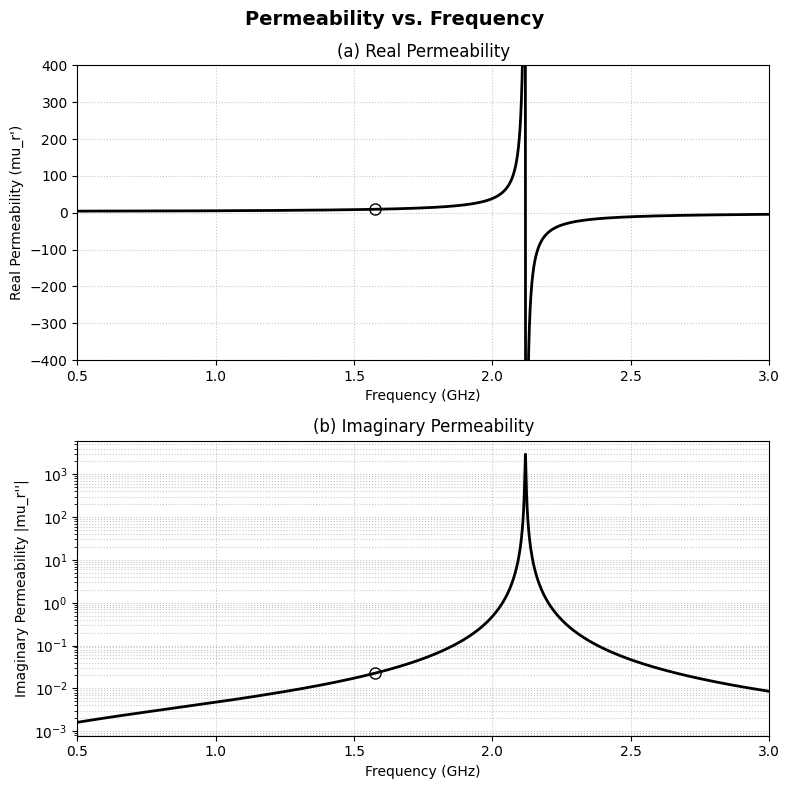

In [32]:
fig2, (ax2a, ax2b) = plt.subplots(2, 1, figsize=(8, 8))
fig2.suptitle("Permeability vs. Frequency", fontsize=14, fontweight='bold')

ax2a.plot(freq_GHz, mr_sweep, 'k-', linewidth=2, label="Real Permeability")
ax2a.plot(freq_GHz[idx_gps], mr_sweep[idx_gps], 'ko', markerfacecolor='none', markersize=8)
ax2a.set_xlabel("Frequency (GHz)")
ax2a.set_ylabel("Real Permeability (mu_r')")
ax2a.set_title("(a) Real Permeability")
ax2a.set_xlim([0.5, 3.0])
ax2a.set_ylim([-400, 400])
ax2a.grid(True, linestyle=':', alpha=0.7)

ax2b.semilogy(freq_GHz, np.abs(mi_sweep), 'k-', linewidth=2, label="Imaginary Permeability")
ax2b.plot(freq_GHz[idx_gps], abs(mi_sweep[idx_gps]), 'ko', markerfacecolor='none', markersize=8)
ax2b.set_xlabel("Frequency (GHz)")
ax2b.set_ylabel("Imaginary Permeability |mu_r''|")
ax2b.set_title("(b) Imaginary Permeability")
ax2b.set_xlim([0.5, 3.0])
ax2b.grid(True, which='both', linestyle=':', alpha=0.7)

fig2.tight_layout()
fig2.savefig('permeability_vs_freq.png', dpi=150, bbox_inches='tight')
plt.show()


In [33]:
def build_8fold_symmetric_grid(bits_36):
    n = 16
    half = n // 2
    corner = np.zeros((half, half), dtype=int)
    idx = 0
    for r in range(half):
        for c in range(r + 1):
            corner[r, c] = bits_36[idx]
            idx += 1

    grid = np.zeros((n, n), dtype=int)
    idx = 0
    for r in range(half):
        for c in range(r + 1):
            val = bits_36[idx]
            idx += 1
            for pr, pc in {
                (r, c), (c, r),
                (r, n-1-c), (n-1-c, r),
                (n-1-r, c), (c, n-1-r),
                (n-1-r, n-1-c), (n-1-c, n-1-r),
            }:
                grid[pr, pc] = val
    return corner, grid

snowflake_bits = [
    1,
    1, 0,
    1, 0, 1,
    0, 0, 0, 1,
    1, 0, 1, 0, 1,
    1, 0, 0, 0, 0, 0,
    1, 0, 1, 0, 1, 0, 1,
    1, 1, 1, 1, 1, 1, 1, 1,
]


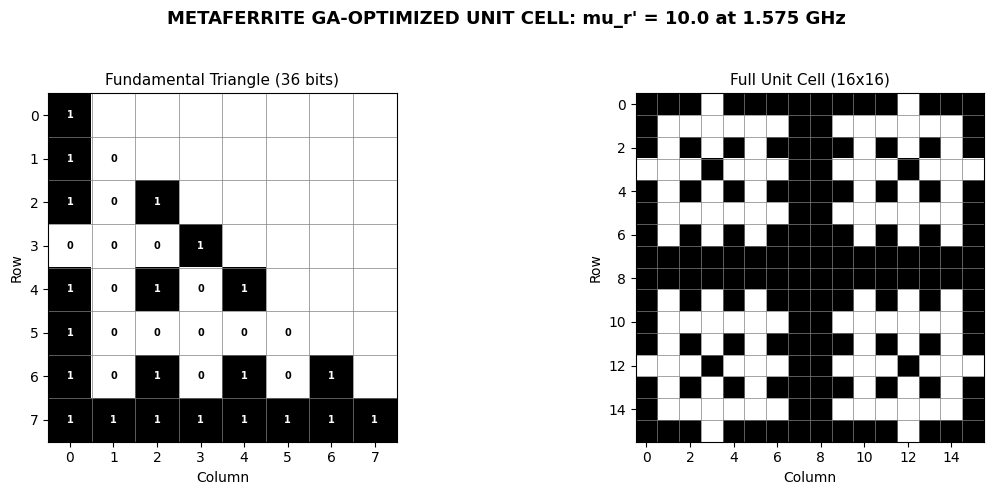


All figures saved successfully!


In [34]:
corner_8x8, full_16x16 = build_8fold_symmetric_grid(snowflake_bits)

triangle_display = np.full((8, 8), np.nan)
idx = 0
for r in range(8):
    for c in range(r + 1):
        triangle_display[r, c] = snowflake_bits[idx]
        idx += 1

fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(12, 5))
fig3.suptitle("METAFERRITE GA-OPTIMIZED UNIT CELL: mu_r' = 10.0 at 1.575 GHz", fontsize=13, fontweight='bold')

ax3a.imshow(triangle_display, cmap='binary', interpolation='nearest', vmin=0, vmax=1)
ax3a.set_title("Fundamental Triangle (36 bits)", fontsize=11)
ax3a.set_xlabel("Column")
ax3a.set_ylabel("Row")
for r in range(8):
    for c in range(8):
        if not np.isnan(triangle_display[r, c]):
            color = 'white' if triangle_display[r, c] == 1 else 'black'
            ax3a.text(c, r, int(triangle_display[r, c]), ha='center', va='center', color=color, fontsize=7, fontweight='bold')

ax3b.imshow(full_16x16, cmap='binary', interpolation='nearest')
ax3b.set_title("Full Unit Cell (16x16)", fontsize=11)
ax3b.set_xlabel("Column")
ax3b.set_ylabel("Row")

for ax in [ax3a, ax3b]:
    ax.set_xticks(np.arange(-0.5, ax.get_xlim()[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, ax.get_ylim()[0], 1), minor=True)
    ax.grid(which='minor', color='gray', linewidth=0.5)
    ax.tick_params(which='minor', size=0)

fig3.tight_layout(rect=[0, 0.0, 1, 0.95])
fig3.savefig('unit_cell_diagram.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nAll figures saved successfully!")
